# 02 · EMT-TF Expression — Liu et al. 2021 (Multiple Myeloma, 10x)

The EMT-transcription-factor readout is **unconditional** — produced regardless of the gate
outcome. Gate 1 was a **NO-GO** (per-patient clonal archipelago; notebook 01), so **no trajectory
is fit** and this is the *last* notebook, numbered **02** (§6 renumbering rule: Gate 1 NO-GO →
01 + 02). We read the malignant cells from `processed.h5ad` and overlay the most informative EMT
transcription factors on the best-attempt manifold, **gated on detectable expression**. No
pseudotime is available or claimed. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the processed malignant manifold
(§6: the expression step reads `processed.h5ad`.) Gate 1 was a NO-GO, so these are the raw
malignant plasma cells on the best-attempt (patient-segregated) embedding — no pseudotime.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())

cells: 17003 | samples: 15 | patients: 10


### Derive the most informative EMT-TFs (data-driven, detection-gated)
The candidate panel widens the canonical Snail / Zeb / Twist factors with the mesenchymal
**FOXC** and **PRRX** families (Kürten evaluation lesson: the canonical panel alone can miss the
informative factor). **VIM is deliberately excluded** — vimentin is a mesenchymal *marker*, not a
transcription factor (Chen testing lesson). With Gate 1 a NO-GO there is no pseudotime axis, so we
rank candidates by **detection fraction** and show the two most broadly-expressed detectable
factors (>3% expressing), so the overlay reflects real signal rather than a handful of
dropout-driven cells.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]
    rows.append((g, round((x>0).mean(),3), round(x[x>0].mean() if (x>0).any() else 0,3), round(float(x.max()),2)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_in_expr','max']).sort_values('frac_expr', ascending=False)
print('EMT-TF candidate panel on Liu 2021 malignant cells:')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
sel = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac>0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

EMT-TF candidate panel on Liu 2021 malignant cells:
    TF  frac_expr  mean_in_expr  max
  ZEB1      0.111         0.388 2.10
  ZEB2      0.047         0.424 1.90
 SNAI1      0.010         0.326 1.54
 SNAI2      0.003         0.559 1.70
TWIST1      0.003         0.303 1.46
 FOXC1      0.002         0.733 1.70
TWIST2      0.000         0.528 1.39
 PRRX1      0.000         0.620 1.31

detectable EMT-TFs (frac>0.03): ['ZEB1', 'ZEB2']
shown (two broadest): ['ZEB1', 'ZEB2']


### EMT-TF expression overlay (deliverable)
`expression.pdf` — house categorical overlay: thresholded expressers of each factor drawn on a grey
manifold (**not** a continuous colormap; Sun testing lesson). Threshold = top decile among
expressing cells per factor, so a broadly-expressed TF is not washed across the manifold. No
pseudotime ordering is implied — Gate 1 was a NO-GO.

overlay thresholds (top decile among expressers): {'ZEB1': 0.71, 'ZEB2': 1.0} | cells shown: {'ZEB1': 190, 'ZEB2': 81}
ZEB1: 11.1% expressing; 190 shown (top decile)
ZEB2: 4.7% expressing; 81 shown (top decile)
saved expression.pdf


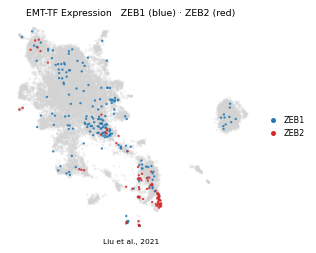

In [5]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g],2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))
colors = {sel[0]:'tab:blue', sel[1]:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=5,label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.06, 'Liu et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in sel:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (top decile)')
print('saved expression.pdf')